> 🇬🇧 [English](../docs/es/../investment_research.md) · 🇪🇸 Español

# Investigación de carteras y análisis técnico y fundamental

Estas incorporaciones experimentales de **6.1.0, aún no publicada**, amplían
`puremacro.asset_pricing`. Funcionan sin conexión con datos proporcionados por el
usuario y NumPy/SciPy/pandas. Siguen disponibles las [pruebas de riesgo y valoración
de activos](../docs/es/asset_pricing.md). No requieren intermediario, suscripción de datos ni
nuevas dependencias de ejecución. Los ejemplos usan datos sintéticos; sus
rendimientos no acreditan rentabilidad de inversión.

El [plan de hitos](../docs/es/../investment_research_milestones.md) registra alcance y evidencia.
Los cuadernos ejecutables son `notebooks/investment_research.py` y
`notebooks/investment_research_es.py`, con sus archivos `.ipynb` ejecutados.

## Evaluación histórica y momento de ejecución

Un rendimiento fechado **t** corresponde al intervalo que termina en el cierre
**t**. La política observa hasta ese cierre y decide. `execution_lag=2`, el valor
predeterminado, ejecuta al cierre siguiente: las nuevas posiciones reciben por
primera vez el rendimiento fechado **t+2**. `execution_lag=1` supone explícitamente
que la decisión podía ejecutarse en su propio cierre. Los rezagos cuentan filas;
el índice proporcionado define el calendario de negociación.

In [1]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib
matplotlib.use("Agg")
repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

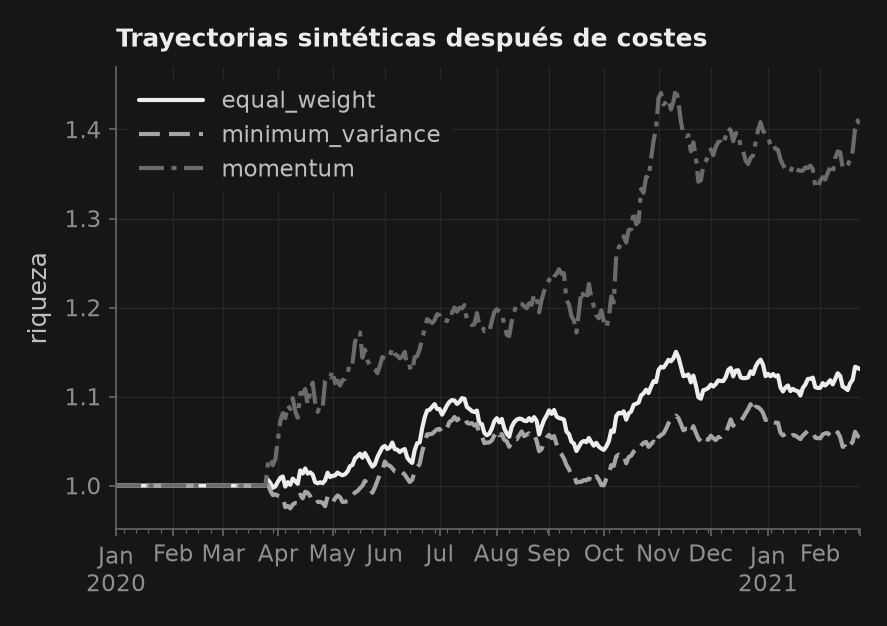

            gross_return  net_return    wealth  turnover  cost   cash_weight  \
2021-02-22     -0.004486   -0.004486  1.055752       0.0   0.0  1.110223e-16   
2021-02-23     -0.001867   -0.001867  1.053781       0.0   0.0  0.000000e+00   

            accounting_residual  
2021-02-22                  0.0  
2021-02-23                  0.0  


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from puremacro import asset_pricing as ap

rng = np.random.default_rng(20261101)
dates = pd.date_range("2020-01-01", periods=300, freq="B")
returns = pd.DataFrame(
    rng.normal([.0002, .0003, .0001], [.008, .014, .006], (300, 3)),
    index=dates, columns=["equity_a", "equity_b", "bond"])
prices = 100 * (1 + returns).cumprod()

def minimum_variance(history):
    covariance = ap.estimate_covariance(history, method="ledoit_wolf")
    return ap.optimize_portfolio(covariance, max_weight=.7).as_series()

policies = {
    "equal_weight": lambda history: ap.equal_weight(history.columns),
    "minimum_variance": minimum_variance,
}
targets = {name: ap.walk_forward_weights(
    returns, policy, min_history=60, window=120, rebalance_every=20)
    for name, policy in policies.items()}
targets["momentum"] = ap.walk_forward_weights(
    prices, lambda history: ap.momentum_weights(history, lookback=40, top_n=2),
    min_history=60, window=120, rebalance_every=20)
runs = {name: ap.backtest_portfolio(returns, weights, cost_bps=15)
        for name, weights in targets.items()}
wealth = pd.DataFrame({name: run.ledger.wealth for name, run in runs.items()})
ax = wealth.plot(title="Trayectorias sintéticas después de costes", ylabel="riqueza")
display(ax.figure)
plt.close(ax.figure)
print(runs["minimum_variance"].ledger.tail(2))

La cartera comienza en efectivo. Una fila de objetivos contiene todos los pesos
o solo NaN (sin rebalanceo); los pesos son no negativos y suman como máximo uno.
El resto es efectivo. Las posiciones cambian de peso entre rebalanceos. Compras
y ventas pagan `cost_bps` sobre el importe del activo; la contrapartida de efectivo
no paga comisión. Con pesos actuales **v**, objetivos después de costes **w** y
tasa de coste **c**, se resuelve `q + c * sum(abs(q*w - v)) = 1`. La riqueza
después de negociar es **q** veces la anterior, sin financiar simultáneamente
posiciones y comisiones con el mismo efectivo.

`ledger` informa rendimientos netos, riqueza, rotación, coste, peso del efectivo y
residuo contable. Rotación y coste son fracciones de la riqueza previa a negociar.
`weights` contiene pesos después de costes y antes del rendimiento; `trades`,
importes con signo divididos por la riqueza previa. `gross_return` describe esas
mismas posiciones después de costes, no otra estrategia simulada sin comisiones.

Se admiten rendimientos ausentes únicamente sin exposición al activo. La ausencia
de un rendimiento de una posición, exposición no elegible o agotamiento de riqueza
produce un error. El marco booleano `eligibility` debe conocerse al inicio de cada
intervalo. Deben proporcionarse rendimientos reales de exclusión de cotización,
ajustes corporativos y decisiones oportunas de liquidación: el motor no inventa
precios ni reconstruye un universo sin sesgo de supervivencia.
Los rendimientos de activos y efectivo deben usar una moneda común de cartera;
no se convierten divisas. Incluya dividendos y otras distribuciones en los
rendimientos totales proporcionados cuando formen parte de la evaluación.
`walk_forward_weights` restringe el historial recibido por la función, pero no
inspecciona su estado externo ni certifica objetivos proporcionados aparte.

In [3]:
record = runs["minimum_variance"].to_json()
replayed = ap.replay_backtest(record)
pd.testing.assert_frame_equal(replayed.ledger, runs["minimum_variance"].ledger)
print("Huella de las entradas:", replayed.input_sha256)

Huella de las entradas: 6faed154df4e54943e1d112b806e46c8cfb81465187237f871f8d802413aa5b3


La repetición conserva entradas fechadas, calendario/zona horaria, objetivos,
elegibilidad y costes. Los calendarios festivos personalizados conservan sus
fechas observadas exactas, no una regla de frecuencia pandas reutilizable.
No guarda funciones ejecutables. La huella detecta cambios
accidentales, sin autenticar datos ni fijar la versión del código. Registre también
la versión de PureMacro y el entorno. Los atributos del resultado son inmutables,
pero sus tablas pandas pueden modificarse; eso no cambia las entradas guardadas.

## Asignación y comparación de estrategias

`estimate_covariance` ofrece covarianza muestral (divisor T−1) y contracción de
Ledoit–Wolf hacia `trace(S)/N * I` (divisor T). No elimina observaciones. Las medias
son descriptivas: el optimizador solo las usa cuando se pasan expresamente como
`expected_returns`.

`optimize_portfolio` minimiza
`risk_aversion/2 * w' Sigma w - return_reward * mu'w + turnover_penalty * ||w-w_prev||1`
con inversión completa, pesos no negativos, límites por activo y un rendimiento
mínimo opcional. La penalización L1 usa restricciones lineales auxiliares. Un
programa lineal independiente sobre el gradiente acota la diferencia respecto al
óptimo convexo. Problemas inviables o soluciones sin certificar generan errores.
`optimality_gap` está en unidades del objetivo; la aceptación compara la brecha
normalizada y la violación de restricciones con `tolerance`. No hay sustitución
silenciosa por pesos iguales ni regularización oculta de la covarianza.
Una varianza final negativa genera un error, incluso si un autovalor negativo
pequeño queda dentro de la tolerancia de redondeo de la descomposición.

Use pesos reales previos a negociar en `previous_weights` para penalizar cambios
desde las posiciones actuales. Esa preferencia no sustituye las comisiones del
registro histórico. Momentos, objetivos y penalizaciones deben compartir unidades
temporales. `efficient_frontier` recibe rendimientos mínimos explícitos; los
inferiores al rendimiento de mínima varianza repiten esa cartera.

In [4]:
covariance = ap.estimate_covariance(returns.iloc[:150])
frontier = ap.efficient_frontier(
    covariance, expected_returns=np.array([.0002, .0003, .0001]),
    targets=[.00012, .00018, .00024], max_weight=.7)
print(frontier.round(6))

# La familia candidata y sus parámetros se fijaron antes de esta muestra.
net = pd.DataFrame({name: run.ledger.net_return for name, run in runs.items()})
evaluation = net.iloc[150:]
comparison = ap.compare_strategies(
    evaluation[["minimum_variance", "momentum"]], evaluation.equal_weight,
    block_length=10, n_boot=499, seed=7)
print(comparison.to_dataframe())
print("Valor p global de la prueba del máximo:", comparison.global_pvalue)
print(ap.risk_summary(evaluation, periods_per_year=252).summary())

   target_return  expected_return  volatility  optimality_gap  \
0        0.00012         0.000159    0.004856             0.0   
1        0.00018         0.000180    0.005050             0.0   
2        0.00024         0.000240    0.007193             0.0   

   weight:equity_a  weight:equity_b  weight:bond  
0         0.331284         0.128605     0.540111  
1         0.393241         0.203380     0.403380  
2         0.568998         0.415501     0.015501  
           strategy  mean_difference  ci_lower_pointwise  ci_upper_pointwise  \
0  minimum_variance        -0.000422           -0.000866            0.000036   
1          momentum         0.000769           -0.000304            0.001671   

   pvalue_max_test  
0             1.00  
1             0.09  
Valor p global de la prueba del máximo: 0.09
Risk summary (T = 150, 252 periods/year, Sharpe se: Lo (2002) HAC, Bartlett lags = 4)
  name             mean      vol   Sharpe     (se)  Sortino   maxDD   dur
  equal_weight   0.1178   

Se usan bloques circulares conjuntos que preservan dependencia entre estrategias.
El máximo centrado, unilateral y sin studentizar contrasta si algún candidato
mejora la media aritmética del rendimiento neto del referente. La corrección de
Monte Carlo es `(exceedances+1)/(B+1)`. Los valores p cubren la familia incluida;
los intervalos son **puntuales**, no simultáneos. Estacionariedad y dependencia
débil apropiada son supuestos, no garantías comprobadas. Incluya todas las
configuraciones exploradas en la muestra de evaluación. No se corrigen búsquedas
omitidas, cambios de régimen ni costes ausentes. La división ilustrativa es
sintética, no una confirmación empírica independiente.

## Indicadores técnicos

In [5]:
indicators = ap.technical_indicators(prices)
print(indicators["equity_a"][["rsi", "macd", "momentum"]].tail(3))

indicator         rsi      macd  momentum
2021-02-19  35.921433 -1.032568 -0.035163
2021-02-22  29.264648 -1.121650 -0.048224
2021-02-23  32.222004 -1.153966 -0.051117


Las columnas son `(asset, indicator)` y conservan los NaN iniciales. SMA y EMA
utilizan datos hasta el cierre actual. EMA comienza con una media simple y sigue
con `alpha=2/(span+1)`. MACD resta las EMA rápida y lenta inicializadas por separado;
su señal empieza con la primera media completa de valores MACD válidos. Otros
proveedores pueden inicializar de otra forma. RSI usa `alpha=1/period` de Wilder
y asigna 50 a una serie constante. Las bandas de Bollinger usan desviación
poblacional (`ddof=0`). Los máximos/mínimos de ruptura excluyen el cierre actual.
`momentum_weights` exige precios positivos completos en la ventana final, resuelve
empates por nombre de activo y conserva efectivo sin momentum positivo. Son
observaciones, no pruebas de predictibilidad; el evaluador aplica el rezago.

## Fundamentos disponibles en la fecha de valoración

In [6]:
facts = pd.DataFrame({
    "asset": ["example", "example"], "metric": ["free_cash_flow"] * 2,
    "unit": ["USD_millions"] * 2, "period_type": ["annual"] * 2,
    "period_start": ["2019-01-01"] * 2, "period_end": ["2019-12-31"] * 2,
    "available_at": ["2020-03-01", "2021-03-01"], "value": [100., 80.],
    "source": ["original_filing", "restatement"],
})
historical = ap.fundamentals_asof(facts, "2020-04-01")
print(historical[["asset", "value", "available_at", "source"]])

# El crecimiento previsto es un supuesto explícito del analista.
cash_flows = historical.value.iloc[0] * 1.04 ** np.arange(1, 6)
valuation = ap.discounted_cash_flow(
    cash_flows, .10, terminal_growth=.02, kind="firm",
    net_debt=200, shares_outstanding=10)
print(valuation.summary())
sensitivity = ap.valuation_sensitivity(
    cash_flows, [.08, .10, .12], [.01, .02, .03],
    net_debt=200, shares_outstanding=10)
print(sensitivity)
print("Valor por acción con dividendos:", ap.dividend_discount(2., .10, .03).value_per_share)

     asset  value              available_at           source
0  example  100.0 2020-03-01 00:00:00+00:00  original_filing
           metric       value
 enterprise_value 1387.087374
     equity_value 1187.087374
  value_per_share  118.708737
      forecast_pv  423.894068
      terminal_pv  963.193306
terminal_fraction    0.694400
   discount_rate  terminal_growth  value_per_share  terminal_fraction status
0           0.08             0.01       144.184692           0.727677     ok
1           0.08             0.02       165.476983           0.758939     ok
2           0.08             0.03       195.286190           0.792317     ok
3           0.10             0.01       107.167205           0.666664     ok
4           0.10             0.02       118.708737           0.694400     ok
5           0.10             0.03       133.547850           0.723934     ok
6           0.12             0.01        83.640742           0.611610     ok
7           0.12             0.02        90.669877  

Cada dato identifica activo, métrica, unidad, tipo de periodo, fin de periodo,
disponibilidad y valor; los flujos también requieren `period_start`. Los tipos son
`instant`, `quarterly`, `annual` y `ttm`. Primero se selecciona la última revisión
disponible de cada intervalo exacto y después el periodo más reciente por
activo/métrica/unidad/tipo. Una revisión posterior de un año antiguo no desplaza
al año más reciente. Las horas sin zona significan UTC; una fecha sola significa
medianoche. Unidades y tipos permanecen separados; duraciones ambiguas generan
errores. Se preserva la procedencia proporcionada, pero no se verifica la fuente,
normalizan taxonomías SEC, convierten acumulados anuales ni construyen flujos TTM.

DCF descuenta flujos al final de cada periodo. `kind="firm"` corresponde a FCFF
descontado al WACC, seguido de la resta de deuda neta. `"equity"` representa FCFE
al coste del capital propio; `"dividend"`, dividendos totales a ese mismo coste.
En esos dos últimos casos no se resta deuda de nuevo. Los vectores de tasas se
capitalizan periodo a periodo. El crecimiento terminal usa permanentemente la
última tasa y exige `-1 < g < r`. Flujos, tasas y acciones deben ser coherentes
en moneda, inflación, escala y periodo. El ejemplo usa dinero y acciones en millones.

`terminal_fraction` muestra la dependencia del valor terminal; las cuadrículas
son escenarios, no intervalos probabilísticos. Las combinaciones inválidas de
tasa y crecimiento conservan su estado. Se mantienen los valores de capital
propio negativos. `fundamental_ratios` calcula múltiplos, márgenes y rendimiento
del flujo libre con entradas comparables explícitas; denominadores no positivos
producen NaN y un estado. Capex es una salida positiva. EV es capitalización +
deuda − efectivo, sin ajustes inferidos de minoritarios o preferentes; ROE usa
el capital contable proporcionado, no su promedio.

## Chartistas y fundamentalistas en un modelo económico

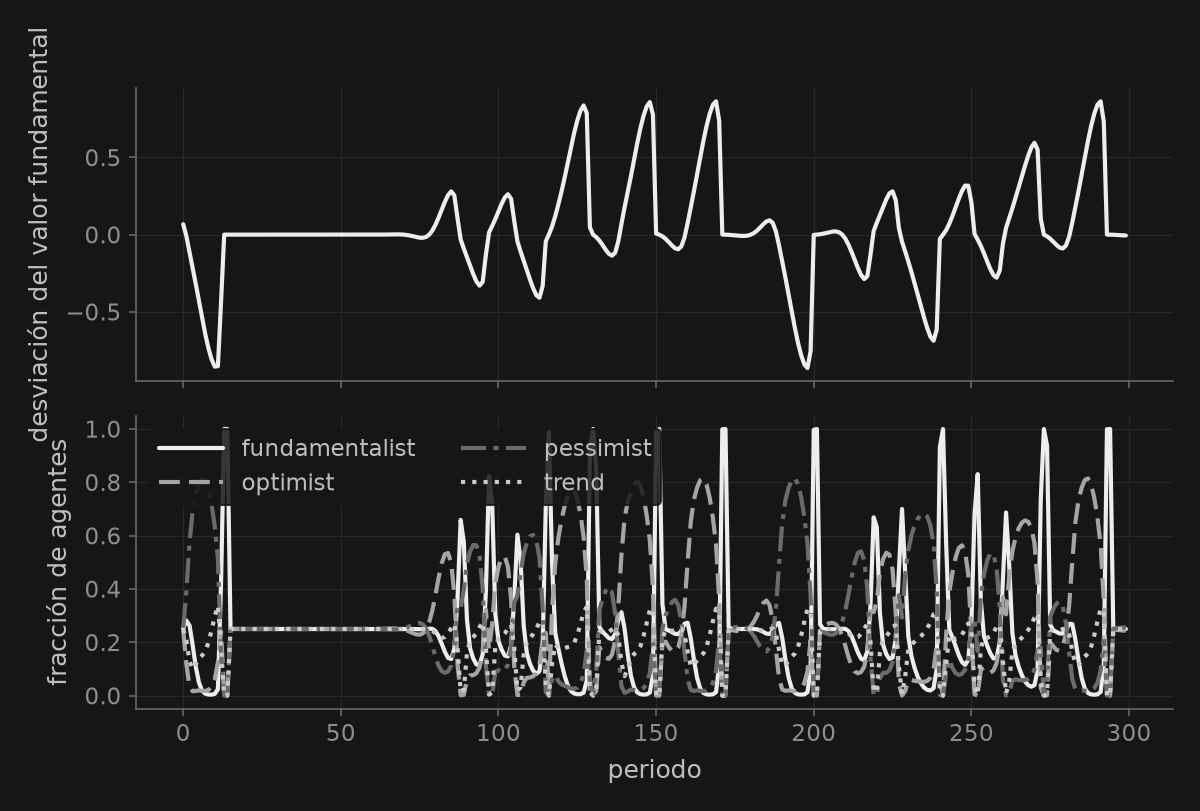

     period  deviation      price  shock_rhs  positive_price  \
298     298  -0.004403  99.995597        0.0            True   
299     299  -0.005492  99.994508        0.0            True   

     fraction:fundamentalist  forecast:fundamentalist  profit:fundamentalist  \
298                 0.249952                      0.0              -0.000004   
299                 0.249925                      0.0              -0.000005   

     fitness:fundamentalist  fraction:optimist  ...  profit:optimist  \
298               -0.000004           0.244220  ...        -0.000273   
299               -0.000005           0.243915  ...        -0.000211   

     fitness:optimist  fraction:pessimist  forecast:pessimist  \
298         -0.000273            0.255856           -0.202715   
299         -0.000211            0.256181           -0.203963   

     profit:pessimist  fitness:pessimist  fraction:trend  forecast:trend  \
298          0.000269           0.000269        0.249972       -0.003047   
2

In [7]:
beliefs = ap.simulate_brock_hommes(
    300, slopes=[0., .9, .9, 1.01], biases=[0., .2, -.2, 0.],
    names=["fundamentalist", "optimist", "pessimist", "trend"],
    intensity=90.5, gross_rate=1.01, risk_scale=1., seed=7)
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(beliefs.deviations)
axes[0].set_ylabel("desviación del valor fundamental")
axes[1].plot(beliefs.fractions, label=beliefs.names)
axes[1].set(xlabel="periodo", ylabel="fracción de agentes")
axes[1].legend(ncol=2)
fig.tight_layout()
display(fig)
plt.close(fig)
print(beliefs.to_dataframe().tail(2))

Es el modelo de reglas afines de Brock–Hommes con oferta externa nula, valor
fundamental y dividendo esperado constantes y rendimiento bruto libre de riesgo
**R > 1**:

```text
f[h,t] = g[h] * x[t-1] + b[h]
n[h,t] = softmax(intensity * U[h,t-1])
R*x[t] = sum_h n[h,t]*f[h,t] + shock[t]
profit[h,t] = (x[t]-R*x[t-1]) * (g[h]*x[t-2]+b[h]-R*x[t-1]) / risk_scale - cost[h]
U[h,t] = profit[h,t] + memory*U[h,t-1]
```

Las fracciones determinan el precio actual; la aptitud se actualiza después. Las
desviaciones iniciales son `x[-3], x[-2], x[-1]`; la aptitud inicial predeterminada
es su beneficio realizado con aptitud acumulada anterior cero. `initial_fitness`
permite cambiarla. `risk_scale` es riesgo percibido por aversión al riesgo, **no**
la varianza del choque simulado. Los choques explícitos entran en el lado derecho
de la ecuación de equilibrio; `noise_std` y `seed` generan una alternativa reproducible.

Los parámetros ilustran la familia de cuatro tipos descrita por Hommes; no se
afirma que esta inicialización reproduzca una trayectoria caótica digitalizada
de una figura. Costes y memoria son extensiones explícitas. Pendiente y sesgo nulos
definen al fundamentalista, no previsión perfecta. Una divergencia genera un error
con el periodo correspondiente; no se recortan precios. Los precios implícitos
negativos se señalan en la tabla y no deben introducirse silenciosamente en
estrategias que exigen precios positivos. Una simulación acotada no prueba
estabilidad global ni ajuste empírico.

## Validación y fuentes

Las pruebas comparan contabilidad con cálculos manuales y posiciones monetarias
independientes; asignación con soluciones analíticas y una malla densa;
covarianza con productos exteriores explícitos; indicadores con fórmulas escalares;
DCF con valores presentes independientes; y creencias con una recurrencia escalar.
Cambios en datos futuros, revisiones y choques futuros comprueban el uso de
información. El [registro de validación](../docs/es/investment_research_validation.md)
distingue esas pruebas de replicación empírica, ejecución en navegador y publicación.

- Ledoit y Wolf (2004), [contracción de covarianza hacia la identidad](https://www.ledoit.net/ole1_abstract.htm).
- La [implementación RSI de TA-Lib](https://github.com/TA-Lib/ta-lib/blob/main/src/ta_func/ta_RSI.c)
  documenta el suavizado de Wilder; las convenciones de series constantes y EMA
  anteriores son decisiones explícitas de PureMacro.
- Los [materiales de valoración de Damodaran](https://pages.stern.nyu.edu/~adamodar/New_Home_Page/lectures/val.html)
  distinguen valoración de empresa, capital propio y dividendos.
- La [documentación EDGAR de la SEC](https://www.sec.gov/search-filings/edgar-application-programming-interfaces)
  describe una fuente posible; aquí no se implementa un conector SEC en vivo.
- Brock y Hommes (1998), [Heterogeneous beliefs and routes to chaos](https://dare.uva.nl/id/6dd1e171-9295-4300-a4d3-a4cf0144d2ac).
  El orden temporal sigue las ecuaciones 104–111, pp. 48–50, del
  [manuscrito de Hommes](https://cendef.uva.nl/binaries/content/assets/subsites/amsterdam-school-of-economics/amsterdam-school-of-economics-research-institute/cendef/working-papers-2005/chhomwechap2006.pdf).

## Ejercicios

1. Aumente los costes y compare la riqueza neta.
2. Mueva una fecha de publicación más allá de la valoración.
3. Cambie la intensidad de selección conservando los choques.
4. Registre todas las configuraciones antes de evaluar rendimientos reservados.